# **- 머신러닝(딥러닝) 프로젝트 진행 절차**


### - 라이브러리 임포트 
      - 실습에 필요한 라이브러리를 임포트합니다. 

In [2]:
# !pip install numpy pandas

import numpy as np
import pandas as pd
import warnings

# 경고 무시 ( 표시 안되게 )
warnings.filterwarnings("ignore")

# skLearn train_test_split
# 선생님과 결과물을 맞추기 위해 렌덤시드를 강제로 75로 설정 
np.random.seed(75)

# 1. 문제 정의
##### - 농구 선수의 경기 기록을 바탕으로, 그 선수의 포지션을 예측해보도록 하겠습니다.


# 2. 데이터 수집

In [3]:
# 데이터를 수집합니다. 
df_csv = pd.read_csv("./data/csv/basketball_stat.csv")

In [4]:
# 수집된 데이터 샘플 확인
# df_csv.head(-1)
df_csv.info()

# Player : 이름
# Pos : 포지션 
# 3P : 한경기당 삼점슛 평균 개수 
# 2P : 한경기당 이점슛 평균 개수 
# TRB : 한경기당 총 리바운드 평균 개수 
# AST : 한경기당 어시스트 평균 개수 
# STL : 한경기당 스틸 평균 개수 
# BLK : 한경기당 블록슛 평균 개수


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  100 non-null    object 
 1   Pos     100 non-null    object 
 2   3P      100 non-null    float64
 3   2P      100 non-null    float64
 4   TRB     100 non-null    float64
 5   AST     100 non-null    float64
 6   STL     100 non-null    float64
 7   BLK     100 non-null    float64
dtypes: float64(6), object(2)
memory usage: 6.4+ KB


In [5]:
# 수치형인 자료들만 관련 정보를 정리 해준다 
df_csv.describe()

,3P,2P,TRB,AST,STL,BLK
count,100.00000,100.000000,100.000000,100.000000,100.000000,100.00000
mean,1.08200,3.265000,5.030000,1.892000,0.725000,0.69600
std,0.91424,1.843053,3.098599,1.257357,0.343004,0.59661
min,0.00000,0.500000,1.300000,0.200000,0.000000,0.10000
25%,0.00000,1.900000,2.875000,0.975000,0.500000,0.20000
50%,1.30000,2.900000,3.900000,1.500000,0.700000,0.55000
75%,1.80000,4.450000,6.325000,2.600000,0.925000,1.00000
max,3.40000,9.700000,14.100000,5.900000,1.600000,3.00000


In [6]:
# 현재 가지고 있는 데이터에서, 포지션의 갯수를 확인
df_csv.Pos.value_counts()

Pos
SG    50
C     50
Name: count, dtype: int64

# 3. 데이터 시각화 ( 특징 파악 )

##### - 데이터 특징을 바탕으로 한 공간에 시각화 함으로써, 우리는 머신러닝 학습에 필요한 특징과 불필요한 특징을 쉽게 구분 지을 수 있다.

In [7]:
# 시각화 라이브러리 설치 seaborn만 설치해도 의존성 때문에 matplotlib등 여러가지가 같이 설치 됨
# !pip install seaborn
import matplotlib.pyplot as plt
import seaborn as sns

Text(0.5, 1.0, 'STL and 2P')

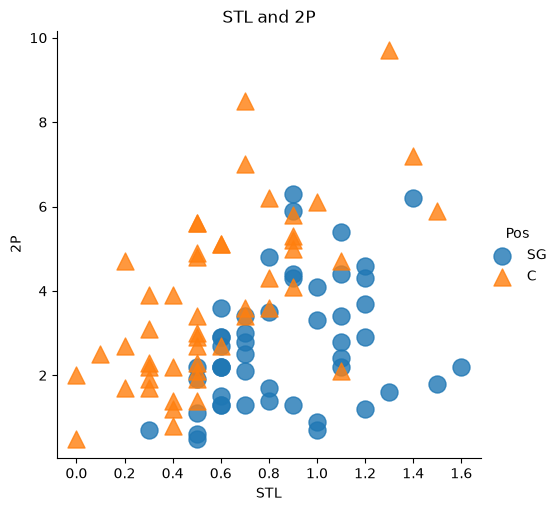

In [8]:
# 'STL(스틸)', '2P(점슛)' 데이터 시각화 
sns.lmplot(data=df_csv, x='STL', y='2P', hue='Pos', 
            fit_reg=False, 
            scatter_kws={'s':150},
            markers=['o', '^'])

plt.title("STL and 2P")



Text(0.5, 1.0, 'AST and 2P')

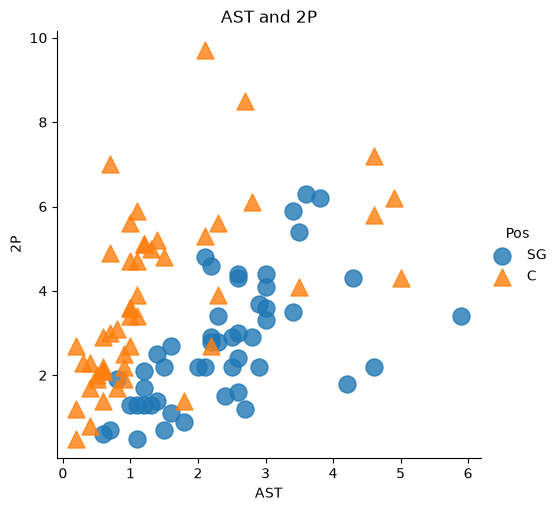

In [9]:
# 'AST(어시스트)', '2P(점슛)' 데이터 시각화 
sns.lmplot(data=df_csv, x='AST', y='2P', hue='Pos', 
            fit_reg=False, 
            scatter_kws={'s':150},
            markers=['o', '^'])

plt.title("AST and 2P")

Text(0.5, 1.0, 'BLK and 3P')

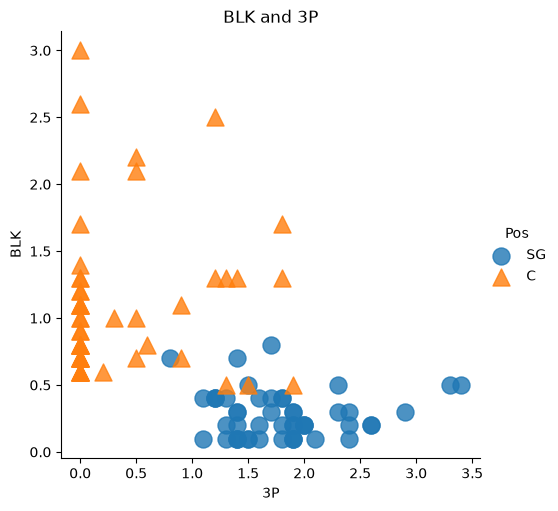

In [10]:
# 'BLK(블로킹)', '3P(점슛)' 데이터 시각화 
sns.lmplot(data=df_csv, x='3P', y='BLK', hue='Pos', 
            fit_reg=False, 
            scatter_kws={'s':150},
            markers=['o', '^'])

plt.title("BLK and 3P")

Text(0.5, 1.0, 'TRB and 3P')

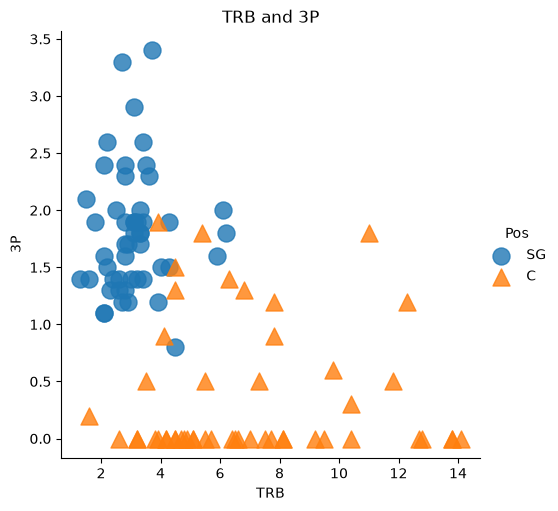

In [87]:
# 'TRB(리바운드)', '3P(점슛)' 데이터 시각화 
sns.lmplot(data=df_csv, x='TRB', y='3P', hue='Pos', 
            fit_reg=False, 
            scatter_kws={'s':150},
            markers=['o', '^'])

plt.title("TRB and 3P")

# 4. 데이터 전처리 ( 다듬기 )

In [89]:
# 분별력이 없는 특징(FEATURE)을 데이터에서 제거.

df_csv.drop(['2P', 'AST', 'STL'], axis=1, inplace=True)
df_csv.head()


,Player,Pos,3P,TRB,BLK
0,Alex Abrines,SG,1.4,1.3,0.1
1,Steven Adams,C,0.0,7.7,1.0
2,Alexis Ajinca,C,0.0,4.5,0.6
3,Chris Andersen,C,0.0,2.6,0.6
4,Will Barton,SG,1.5,4.3,0.5


# 5. 데이터 나누기 ( 학습 데이터, 테스트 데이터 )

In [ ]:
# !pip install scikit-learn

In [ ]:
from sklearn.model_selection import train_test_split

# 다듬어진 데이터에서 20퍼센트를 테스트 데이터로 분류 (렌덤으로!!!)
# train -> 80퍼센트 데이터,  test -> 20퍼센트 데이터
train, test = train_test_split(df_csv, test_size=0.2)

<class 'pandas.core.frame.DataFrame'>


In [94]:
# 학습 데이터의 갯수를 확인 
train.shape[0]


80

In [93]:
# 테스트 데이터의 갯수를 확인 
test.shape[0]

20

# 6. 저장(보관)

In [101]:
train.to_csv("./data/csv/basketball_train.csv", index=None)
test.to_csv("./data/csv/basketball_test.csv", index=None)